In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

np.set_printoptions(precision=3, suppress=True)

In [2]:
iris = load_iris()

In [3]:
X_all, y_all = iris.data, iris.target
print(X_all.shape, y_all.shape, iris.target_names)

(150, 4) (150,) ['setosa' 'versicolor' 'virginica']


In [4]:
from matplotlib.patches import Patch, Circle
from matplotlib.colors import LinearSegmentedColormap, to_rgb

SPECIES = ["setosa", "versicolor", "virginica"]
COLORS  = ["#2a78d6", "#eb6834", "#1baf7a"]   # one colour per species, used in every plot
MARKERS = ["o", "s", "^"]                     # ...and one shape (easier to read on a projector)
INK, INK2, MUTED, LINE, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#c3c2b7", "#e1e0d9", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 100, "font.size": 10, "lines.linewidth": 2,
    "axes.edgecolor": LINE, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "axes.titlepad": 10, "axes.labelcolor": INK2, "axes.labelsize": 10,
    "xtick.color": LINE, "ytick.color": LINE, "xtick.labelcolor": MUTED, "ytick.labelcolor": MUTED,
    "legend.frameon": True, "legend.facecolor": SURFACE, "legend.edgecolor": "none",
    "legend.framealpha": 0.88, "legend.fontsize": 9,
})

In [13]:
def _scatter_species(ax, X, y):
    for k in range(3):
        m = y == k
        ax.scatter(X[m,0], X[m,1], s=42, c=COLORS[k], marker=MARKERS[k],
                   edgecolors=SURFACE, linewidths=0.9, label=SPECIES[k], zorder=3)

def _petal_axes(ax):
    ax.set_xlabel("petal lenght (cm)")
    ax.set_ylabel("petal width (cm)")
    ax.set_xlim(0.5, 7.50)
    ax.set_ylim(-0.2, 2.9)

def plot_flowers(X, y):
    fig, ax= plt.subplots(figsize= (5.8, 4.2))
    _scatter_species(ax, X, y)
    _petal_axes(ax)
    ax.set_title("150 iris flowers, two petal measurements")
    ax.legend(loc='upper left')
    plt.show()

def plot_regions(predict, X, y, target, title='', ax=None, legend=True):
    """Shade where predict(X_cm) > 0.5, i.e. where the model answers 'yes, this is a <target>'."""
    standalone = ax is None
    if standalone:
        gif, ax = plt.subplots(figsize=(5.8, 4.2))
    g0, g1 = np.meshgrid(np.linspace(0.5, 7.5, 350), np.linspace(-0.2, 2.9, 350))
    P = np.asarray(predict(np.c_[g0.ravel(), g1.ravel()]), dtype=float).reshape(g0.shape)
    tint = tint(COLORS[target], 0.24)
    ax.contourf(g0, g1, (P > 0.5).astype(float), levels=[-0.5, 0.5, 1.5], colors=[SURFACE, tint], zorder=2)
    if P.min() < 0.5 < P.max():
        ax.contour(g0, g1, P, levels=[0.5], colors=INK, linewidths=1.4, zorder=2)
    ax.grid(False)
    _scatter_species(ax, X, y)
    _petal_axes(ax)
    acc = np.mean((np.asarray(predict(X), dtype=float).ravel() > 0.5) == (y == target))
    acc.set_title(f'{title}\naccuracy {acc: .1%}' if title else f'accuracy {acc:.1%}')
    if legend:
        handles = ax.get_legend_handles_labels()[0]
        handles.append(Patch(facecolor=tint, edgecolor='none', label=f'model says: {SPECIES[target]}'))
        ax.legend(handles=handles, loc='upper left')
    if standalone:
        plt.show()

def show_perceptron(w, b, mistakes, X, y, target):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={'width_ratios': [1, 1.15]})
    epochs = np.arange(1, len(mistakes) + 1)
    ax1.plot(epochs, mistakes, color=INK2, marker='o', markersize=5.5, markeredgecolor=SURFACE, clip_on=False)
    ax1.set_xlabel('epoch')
    ax1.set_ylabel('mistakes during the epoch')
    ax1.set_ylim(0, max(10, max(mistakes) * 1.15))
    ax1.set_title(f'Perceptron learning: {SPECIES[target]} vs. the rest\nmistakes per epoch')
    plot_regions(lambda Xq: (Xq @ w + b > 0).astype(float), X, y, target, title='Final decision boundary', ax=ax2)
    plt.tight_layout()
    plt.show()

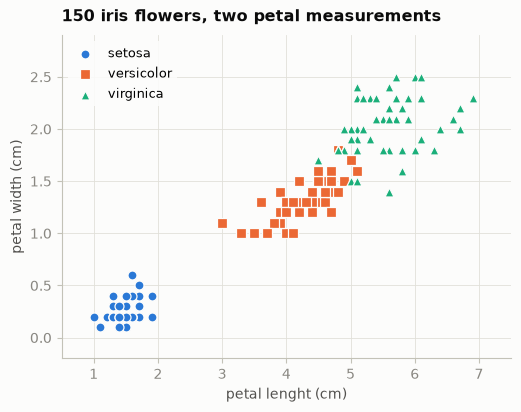

In [14]:
X = X_all[:, 2:]
plot_flowers(X, y_all)

In [7]:
type(X)

numpy.ndarray

In [ ]:
def step(z):
    return (z > 0).astype(float)

def train_perceptron(X, y, epochs=30, lr=0.1, seed=0):
    rng = np.random.default_rng(seed)
    w, b = np.zeros(X.shape[1]), 0.0
    mistakes_per_epoch = []
    for epoch in range(epochs):
        mistakes = 0
        for i in rng.permutation(len(X)):
            y_hat = step(X[i] @ w + b)
            update = lr * (y[i] - y_hat)
            w += update * X[i]
            b += update
            mistakes += int(y_hat != y[i])
        mistakes_per_epoch.append(mistakes)
    return w, b, mistakes_per_epoch


In [9]:
Peruano = []
No_Peruano = []
def Peruatron(x,A,B):
    if x < 10:
        A.append(x)
    else:
        B.append(x)

Peruatron(20, Peruano, No_Peruano)

In [10]:
No_Peruano

[20]

In [11]:
for i in range(1,30):
    Peruatron(i, Peruano, No_Peruano)

In [12]:
No_Peruano

[20,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23,
 24,
 25,
 26,
 27,
 28,
 29]